# Stochastic Systems: 1D and 2D Random Walks

## 1. Theory & Statistical Mechanics
- 1D Random walk recurrence: $x_n = x_{n-1} + \eta_n$.
- Unbiased walk ($p_r = p_l = 1/2$): $\langle x_n \rangle = 0$, $\langle x_n^2 \rangle = n \implies \text{MSD} = n$.
- Diffusive spreading: $\langle x(t)^2 \rangle = 2 D t$ where $D = \frac{\Delta x^2}{2 \Delta t}$.
- 2D Random walk: $\mathbf{R}_n = x_n \hat{\mathbf{i}} + y_n \hat{\mathbf{j}}$, $\langle |\mathbf{R}_n|^2 \rangle = \langle x_n^2 \rangle + \langle y_n^2 \rangle = 2n$.
- Single noisy realization vs. smooth ensemble average over $N_{\text{re}}$ paths.

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 4.1)
1D Discrete Random Walk simulation, first 10 individual trajectories, ensemble mean $\langle x \rangle$, spread envelope $\pm\sqrt{n}$, and linear MSD $\langle x^2 \rangle = n$.

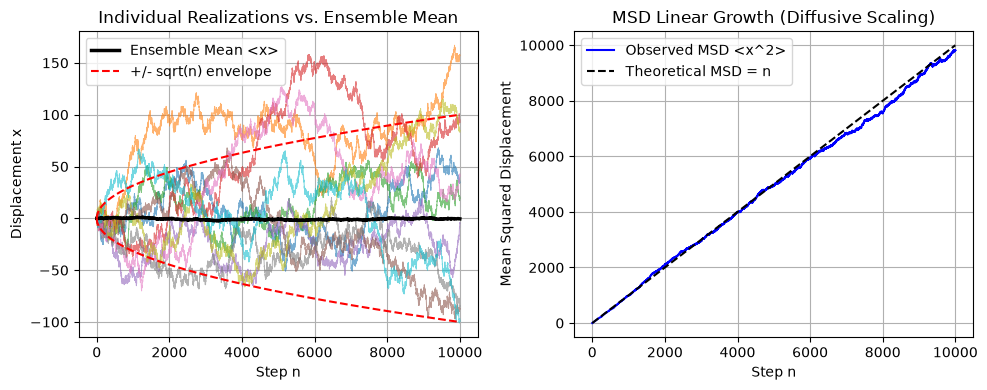

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 10000          # Number of steps
Nre = 1000         # Number of realizations (ensemble size)

# Initialize arrays
msd = np.zeros((N, Nre))
X = np.zeros((N, Nre))

# Simulation Loop over realizations
for ire in range(Nre):
    # Vectorized step generation: +1 with p=0.5, -1 with p=0.5
    steps = np.where(np.random.rand(N) >= 0.5, 1, -1)
    steps[0] = 0  # Initial position x_0 = 0
    x = np.cumsum(steps)
    
    X[:, ire] = x
    msd[:, ire] = x**2

# Ensemble averages across realizations
avgX = np.mean(X, axis=1)
avgMSD = np.mean(msd, axis=1)
steps_axis = np.arange(N)

# Plotting
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
for i in range(10): # Plot first 10 individual realizations
    plt.plot(steps_axis, X[:, i], lw=0.7, alpha=0.6)
plt.plot(steps_axis, avgX, 'k-', lw=2.5, label='Ensemble Mean <x>')
plt.plot(steps_axis, np.sqrt(steps_axis), 'r--', label='+/- sqrt(n) envelope')
plt.plot(steps_axis, -np.sqrt(steps_axis), 'r--')
plt.xlabel('Step n'); plt.ylabel('Displacement x')
plt.title('Individual Realizations vs. Ensemble Mean')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(steps_axis, avgMSD, 'b-', label='Observed MSD <x^2>')
plt.plot(steps_axis, steps_axis, 'k--', label='Theoretical MSD = n')
plt.xlabel('Step n'); plt.ylabel('Mean Squared Displacement')
plt.title('MSD Linear Growth (Diffusive Scaling)')
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

## 3. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 4.2)
2D Random Walk Mean Squared Displacement $\langle R^2 \rangle = 2n$ verification.

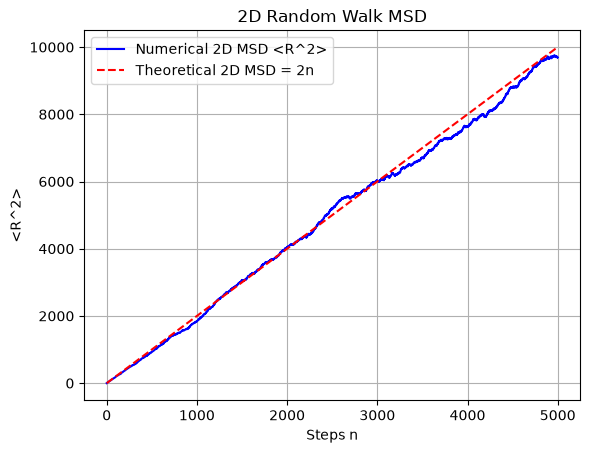

In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 5000
Nre = 500

R_sq = np.zeros((N, Nre))

for ire in range(Nre):
    step_x = np.where(np.random.rand(N) >= 0.5, 1, -1); step_x[0] = 0
    step_y = np.where(np.random.rand(N) >= 0.5, 1, -1); step_y[0] = 0
    x = np.cumsum(step_x)
    y = np.cumsum(step_y)
    R_sq[:, ire] = x**2 + y**2

avg_R_sq = np.mean(R_sq, axis=1)
steps = np.arange(N)

plt.plot(steps, avg_R_sq, 'b-', label='Numerical 2D MSD <R^2>')
plt.plot(steps, 2 * steps, 'r--', label='Theoretical 2D MSD = 2n')
plt.xlabel('Steps n'); plt.ylabel('<R^2>'); plt.title('2D Random Walk MSD'); plt.legend(); plt.grid(True); plt.show()


## 4. PROFESSOR'S IN-CLASS CODE (from `Notes/randomwalk_1D.ipynb`)
This is the code as directly written in `Notes/randomwalk_1D.ipynb` ($N = 20000$ steps, $N_{\text{re}} = 1000$ realizations).

Final avgX: 2.226
Final avgMSD: 20942.608


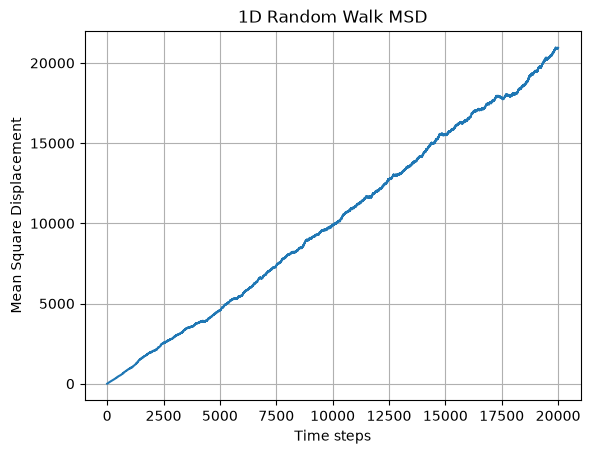

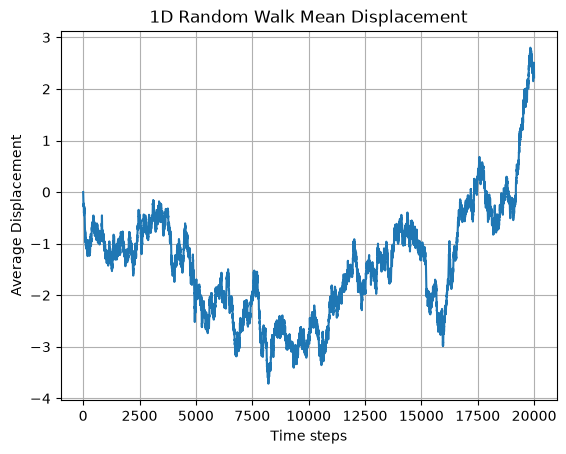

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 20000       # Number of steps/iterations
Nre = 1000      # Number of realizations

# Initialize arrays
x = np.zeros(N)                 # Displacement of the walker
msd = np.zeros((N, Nre))        # Mean square displacement
X = np.zeros((N, Nre))          # Displacement for different realizations

# Realization loop
for ire in range(Nre):

    x[0] = 0 # Initial position
    
    # Temporal iteration loop
    for i in range(1, N):

        rd = np.random.rand()  # Random number for displacement

        if rd >= 0.5:
            x[i] = x[i-1] + 1
        else:
            x[i] = x[i-1] - 1

    # Store displacement and MSD
    msd[:, ire] = x**2
    X[:, ire] = x

# Calculate averages over realizations
avgX = np.mean(X, axis=1)
avgMSD = np.mean(msd, axis=1)

print("Final avgX:", avgX[-1])
print("Final avgMSD:", avgMSD[-1])

# Plot mean square displacement
plt.plot(avgMSD)
plt.xlabel('Time steps')
plt.ylabel('Mean Square Displacement')
plt.title('1D Random Walk MSD')
plt.grid(True)
plt.show()

plt.figure()
plt.plot(avgX)
plt.xlabel('Time steps')
plt.ylabel('Average Displacement')
plt.title('1D Random Walk Mean Displacement')
plt.grid(True)
plt.show()